In [1]:
import sys
import os
os.chdir("/home/neillucha/SNU/proj/MUL/spm_unlearning")
repo_root = os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("repo_root:", repo_root)
print("sys.path:", sys.path)
import json
import pandas as pd
import matplotlib.pyplot as plt
from scripts.eval_checkpoint_paired import evaluate_paired

repo_root: /home/neillucha/SNU/proj/MUL/spm_unlearning
sys.path: ['/home/neillucha/SNU/proj/MUL/spm_unlearning', '/home/neillucha/miniconda3/envs/spm/lib/python310.zip', '/home/neillucha/miniconda3/envs/spm/lib/python3.10', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/lib-dynload', '', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/site-packages']


In [2]:
import sys
import os
os.chdir("/home/neillucha/SNU/proj/MUL/spm_unlearning")
repo_root = os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("repo_root:", repo_root)
print("sys.path:", sys.path)
import json
import pandas as pd
import matplotlib.pyplot as plt
from scripts.eval_checkpoint_paired import evaluate_paired

repo_root: /home/neillucha/SNU/proj/MUL/spm_unlearning
sys.path: ['/home/neillucha/SNU/proj/MUL/spm_unlearning', '/home/neillucha/miniconda3/envs/spm/lib/python310.zip', '/home/neillucha/miniconda3/envs/spm/lib/python3.10', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/lib-dynload', '', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/site-packages']


# Unlearning and deletion robustness analysis

This notebook has two complementary evaluation sections:

1. **Four-split unlearning evaluation**: analyze the JSON produced by `evaluate.py` with `evaluate_unlearn()`. This measures forget/retain train and test accuracy, SVC membership inference, and (when `--retrain --acc_v2` is used) agreement and KL divergence against a retain-only retrained reference model.
2. **Paired support-deletion robustness**: optionally compare the original and deletion-aware checkpoints with identical support episodes and deletion masks using `scripts/eval_checkpoint_paired.py`.

The deletion-aware variant can now use the four-split evaluator with its deletion configuration. The paired evaluator remains useful for measuring robustness as a controlled fraction of support samples is removed.

In [3]:
import sys
import os
os.chdir("/home/neillucha/SNU/proj/MUL/spm_unlearning")
# evaluation/ -> spm_unlearning/
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

print("repo_root:", repo_root)
print("sys.path:", sys.path)

import json
import pandas as pd
import matplotlib.pyplot as plt

from scripts.eval_checkpoint_paired import evaluate_paired

repo_root: /home/neillucha/SNU/proj/MUL
sys.path: ['/home/neillucha/SNU/proj/MUL', '/home/neillucha/SNU/proj/MUL/spm_unlearning', '/home/neillucha/miniconda3/envs/spm/lib/python310.zip', '/home/neillucha/miniconda3/envs/spm/lib/python3.10', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/lib-dynload', '', '/home/neillucha/miniconda3/envs/spm/lib/python3.10/site-packages']


In [4]:
# Paths: adjust as needed
config = 'config/classification/cifar_resnet18_deletion.yaml'
ckpt_a = 'results/classification/cifar_resnet18_deletion/last.ckpt'  # deletion-aware
ckpt_b = 'results/classification/cifar_resnet18/last.ckpt'          # baseline
out_dir = 'results/eval_paired'
# run paired evaluation (adjust max_batches for a quick smoke test)
res = evaluate_paired(config, ckpt_a, ckpt_b, out_dir=out_dir, max_batches=200, seed=0)
with open(os.path.join(out_dir, 'paired_eval_results.json')) as f:
    data = json.load(f)
# The script stores a 'summary' (aggregated) and 'per_batch' (detailed) sections
# show aggregated summary table
df = pd.DataFrame(data['summary'])
df

Saved paired evaluation to results/eval_paired/paired_eval_results.json


,p,AfullA_mean,AfullA_std,A_p_A_mean,A_p_A_std,DeltaA_mean,DeltaA_std,AfullB_mean,AfullB_std,A_p_B_mean,A_p_B_std,DeltaB_mean,DeltaB_std,Delta_robust_mean,Delta_robust_std
0,0.0,0.937012,0.015017,0.937012,0.015017,0.000000,0.000000,0.944531,0.015454,0.944531,0.015454,0.000000,0.000000,0.000000,0.000000
1,0.1,0.937012,0.015017,0.937207,0.015022,-0.000195,0.000862,0.944531,0.015454,0.944434,0.015308,0.000098,0.001079,0.000293,0.001367
2,0.2,0.937012,0.015017,0.937207,0.014918,-0.000195,0.001235,0.944531,0.015454,0.944336,0.015366,0.000195,0.001235,0.000391,0.001938
3,0.4,0.937012,0.015017,0.937109,0.015033,-0.000098,0.001652,0.944531,0.015454,0.944531,0.015095,0.000000,0.001532,0.000098,0.002253
4,0.6,0.937012,0.015017,0.937402,0.014920,-0.000391,0.001480,0.944531,0.015454,0.944531,0.015352,0.000000,0.001532,0.000391,0.002130
5,0.8,0.937012,0.015017,0.937012,0.014648,0.000000,0.002502,0.944531,0.015454,0.944434,0.015360,0.000098,0.001652,0.000098,0.003367
6,0.9,0.937012,0.015017,0.936719,0.014834,0.000293,0.003237,0.944531,0.015454,0.944434,0.015436,0.000098,0.001874,-0.000195,0.003748


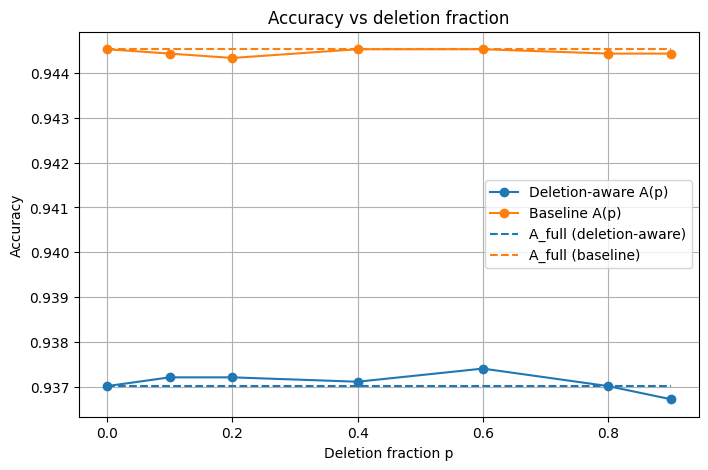

In [5]:
# Plot accuracies vs p (means)
plt.figure(figsize=(8,5))
plt.plot(df['p'], df['A_p_A_mean'], marker='o', label='Deletion-aware A(p)')
plt.plot(df['p'], df['A_p_B_mean'], marker='o', label='Baseline A(p)')
# plot full-support baselines as dashed lines
plt.plot(df['p'], df['AfullA_mean'], '--', color='C0', label='A_full (deletion-aware)')
plt.plot(df['p'], df['AfullB_mean'], '--', color='C1', label='A_full (baseline)')
plt.xlabel('Deletion fraction p')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy vs deletion fraction')
plt.grid(True)
plt.show()

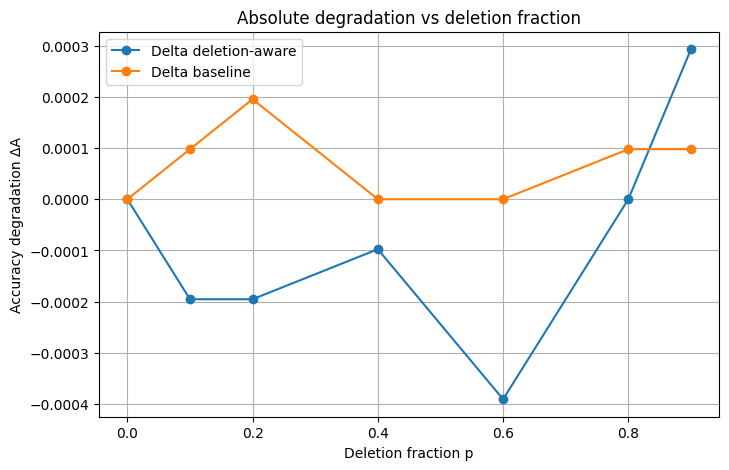

In [6]:
# Plot absolute degradation Delta = A_full - A(p)
plt.figure(figsize=(8,5))
plt.plot(df['p'], df['DeltaA_mean'], marker='o', label='Delta deletion-aware')
plt.plot(df['p'], df['DeltaB_mean'], marker='o', label='Delta baseline')
plt.xlabel('Deletion fraction p')
plt.ylabel('Accuracy degradation ΔA')
plt.legend()
plt.title('Absolute degradation vs deletion fraction')
plt.grid(True)
plt.show()

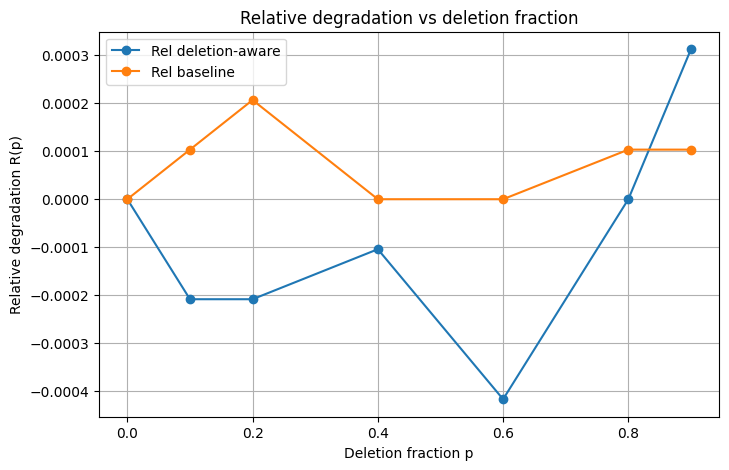

In [7]:
# Plot relative degradation R(p)
plt.figure(figsize=(8,5))
plt.plot(df['p'], df['DeltaA_mean'] / df['AfullA_mean'], marker='o', label='Rel deletion-aware')
plt.plot(df['p'], df['DeltaB_mean'] / df['AfullB_mean'], marker='o', label='Rel baseline')
plt.xlabel('Deletion fraction p')
plt.ylabel('Relative degradation R(p)')
plt.legend()
plt.title('Relative degradation vs deletion fraction')
plt.grid(True)
plt.show()

## 1. Analyze four-split unlearning metrics

Run `evaluate.py` first and set `unlearning_json` below to the generated JSON file. For reference-model comparison, the command must include `--retrain --acc_v2`.

In [12]:
# Set this to the JSON written by evaluate.py.
unlearning_json = (
    'results/classification/cifar_resnet18_retrain/1_class/'
    'eval_existing_reference_0.json'
)

with open(unlearning_json) as f:
    unlearning_metrics = json.load(f)

pd.Series(unlearning_metrics).to_frame('value')

,value
spm_model_acc,0.851900
spm_inference_time,1.650570
retrain_spm_model_acc,0.849200
retrain_spm_inference_time,1.458011
ce,1.551850
kl,0.279519
agreement_rate,90.930003
retrain_training_time,0.000000
retain_spm_unl_train_acc_unlearn,0.000000
retain_spm_unl_train_acc_rest,0.999689


In [13]:
accuracy_keys = [
    'train_acc_unlearn', 'train_acc_rest',
    'test_acc_unlearn', 'test_acc_rest',
]
accuracy_df = pd.Series({key: unlearning_metrics.get(key) for key in accuracy_keys}).dropna()
accuracy_df.plot(kind='bar', figsize=(8, 4), title='Forget and retain accuracy', ylabel='Accuracy', ylim=(0, 1), grid=True)
plt.xticks(rotation=25, ha='right')
plt.show()

TypeError: no numeric data to plot

In [11]:
comparison_keys = [
    'confidence_svc', 'prob_svc',
    'test_unlearn_prediction_agreement', 'test_rest_prediction_agreement',
    'test_unlearn_kl', 'test_rest_kl',
]
comparison_df = pd.Series({key: unlearning_metrics.get(key) for key in comparison_keys}).dropna()
comparison_df.to_frame('value')

,value
confidence_svc,0.500000
prob_svc,0.459000
test_unlearn_prediction_agreement,0.580000
test_rest_prediction_agreement,0.945889
test_unlearn_kl,1.058910
test_rest_kl,0.192840


## Commands

For class-based unlearning of class `0`, run from the repository root:

```bash
PYTHONPATH=. python evaluate.py \
  --model_type classifier \
  --config config/classification/cifar_resnet18.yaml \
  --ckpt_path results/classification/cifar_resnet18/last.ckpt \
  --dataset_name cifar10 \
  --query_digits 0 \
  --support_digits 1,2,3,4,5,6,7,8,9 \
  --support_size_eval 256 \
  --batch_size 256 \
  --out_file results/classification/cifar_resnet18/retrain_class_0 \
  --retrain --acc_v2 --seed 0
```

The script appends the seed to the output filename. Set `unlearning_json` in the next cell to that generated JSON, then run the analysis cells. The deletion-aware variant is evaluated separately with `scripts/eval_checkpoint_paired.py`; that command is documented in `README_Deletion.md` and in the paired-evaluation cells above.